# Group 7 — Steam Top Sellers Analysis
**Run this notebook only after collecting real daily data and running `python clean_and_load.py`.**

The notebook uses your collected observations. It does not contain fabricated results.

In [11]:
# check what info python received from the website, 
# whether pYthon received a valid Steam page and whether a few diagnostic strings appear in its HTML. 

import requests
from bs4 import BeautifulSoup


url = "https://store.steampowered.com/charts/topselling/US"

response = requests.get(
    url, 
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

print("Status:", response.status_code)
print("Final URL:", response.url)
print("Content type:", response.headers.get("Content-Type"))
print("HTML length:", len(response.text))

soup = BeautifulSoup(response.text, "html.parser")
page_text = soup.get_text("", strip=True)

for term in ["Top Sellers", "Counter-Strike 2"]:
    print(f"{term!r} in HTML:", term.lower() in response.text.lower())
    print(f"{term!r} in visible text:", term.lower() in page_text.lower())

Status: 200
Final URL: https://store.steampowered.com/charts/topselling/US
Content type: text/html; charset=utf-8
HTML length: 727866
'Top Sellers' in HTML: True
'Top Sellers' in visible text: True
'Counter-Strike 2' in HTML: True
'Counter-Strike 2' in visible text: True


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("../steam_games.db")
if not DB_PATH.exists():
    raise FileNotFoundError("steam_games.db not found. Run the scraper for daily data, then run clean_and_load.py.")

with sqlite3.connect(DB_PATH) as con:
    products = pd.read_sql_query("SELECT * FROM products", con)
    observations = pd.read_sql_query("SELECT * FROM observations", con)

observations["scraped_at"] = pd.to_datetime(observations["scraped_at"], errors="coerce", utc=True)
for col in ["price", "original_price", "discount_percent", "rank"]:
    observations[col] = pd.to_numeric(observations[col], errors="coerce")

print("Unique products:", products["game_id"].nunique())
print("Observations:", len(observations))
print("Collection dates:", observations["scraped_at"].dt.date.nunique())
observations.head()

Unique products: 499
Observations: 499
Collection dates: 1


,observation_id,game_id,scraped_at,rank,price,original_price,discount_percent,review_summary,currency,raw_file
0,1,3393110,2026-10-15 07:32:18+00:00,1,0.00,0.00,0.0,None,USD,steam_top_sellers_20261015_103252.csv
1,2,2929250,2026-10-15 07:32:18+00:00,2,19.99,24.99,20.0,None,USD,steam_top_sellers_20261015_103252.csv
2,3,4231820,2026-10-15 07:32:18+00:00,3,29.99,NaN,NaN,None,USD,steam_top_sellers_20261015_103252.csv
3,4,730,2026-10-15 07:32:18+00:00,4,0.00,0.00,0.0,None,USD,steam_top_sellers_20261015_103252.csv
4,5,3219030,2026-10-15 07:32:18+00:00,5,49.99,NaN,NaN,None,USD,steam_top_sellers_20261015_103252.csv


## 1. Data quality checks

In [2]:
display(observations.isna().sum().to_frame("missing_values"))
display(observations[["price", "original_price", "discount_percent", "rank"]].describe())

,missing_values
observation_id,0
game_id,0
scraped_at,0
rank,0
price,1
original_price,237
discount_percent,237
review_summary,499
currency,0
raw_file,0


,price,original_price,discount_percent,rank
count,498.000000,262.000000,262.000000,499.000000
mean,27.455241,25.772252,32.862595,250.000000
std,63.807251,40.438870,28.529413,144.193157
min,0.000000,0.000000,0.000000,1.000000
25%,7.490000,0.000000,0.000000,125.500000
50%,17.990000,19.990000,30.000000,250.000000
75%,34.572500,39.100000,55.750000,374.500000
max,1049.000000,499.000000,95.000000,499.000000


## 2. Chart 1 — Price distribution

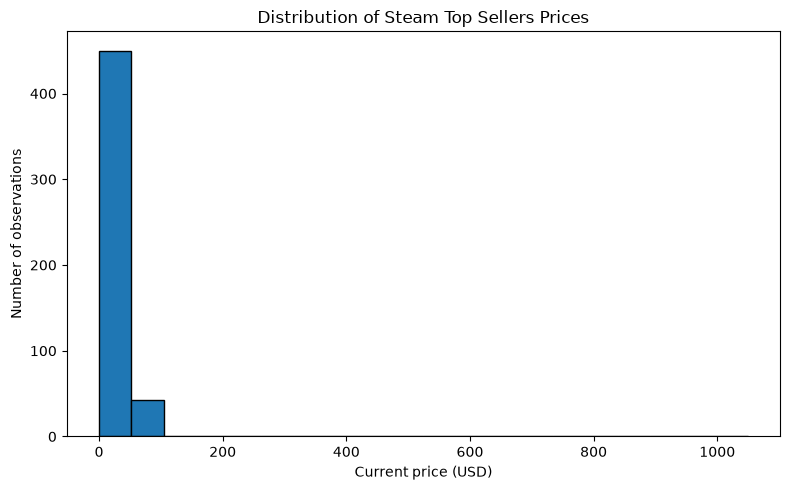

In [3]:
price_data = observations["price"].dropna()
plt.figure(figsize=(8, 5))
plt.hist(price_data, bins=20, edgecolor="black")
plt.xlabel("Current price (USD)")
plt.ylabel("Number of observations")
plt.title("Distribution of Steam Top Sellers Prices")
plt.tight_layout()
plt.show()

## 3. Chart 2 — Price box plot and possible outliers

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10560\939172863.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(observations["price"].dropna(), vert=False)


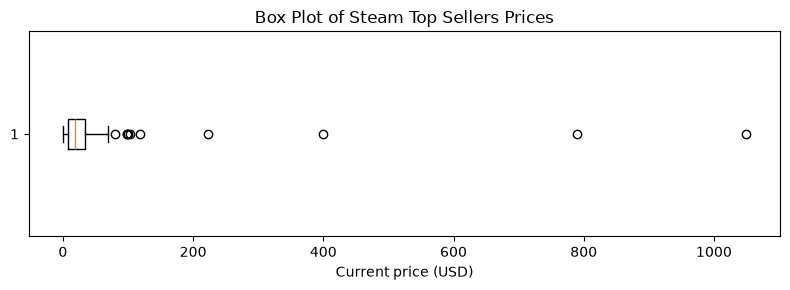

Potential price outlier observations: 10


KeyError: "['title'] not in index"

In [4]:
plt.figure(figsize=(8, 3))
plt.boxplot(observations["price"].dropna(), vert=False)
plt.xlabel("Current price (USD)")
plt.title("Box Plot of Steam Top Sellers Prices")
plt.tight_layout()
plt.show()

q1 = observations["price"].quantile(0.25)
q3 = observations["price"].quantile(0.75)
iqr = q3 - q1
outliers = observations[(observations["price"] < q1 - 1.5*iqr) | (observations["price"] > q3 + 1.5*iqr)]
print("Potential price outlier observations:", len(outliers))
display(outliers[["game_id", "title", "price", "original_price", "scraped_at"]].head(20))

## 4. Chart 3 — Review-summary categories

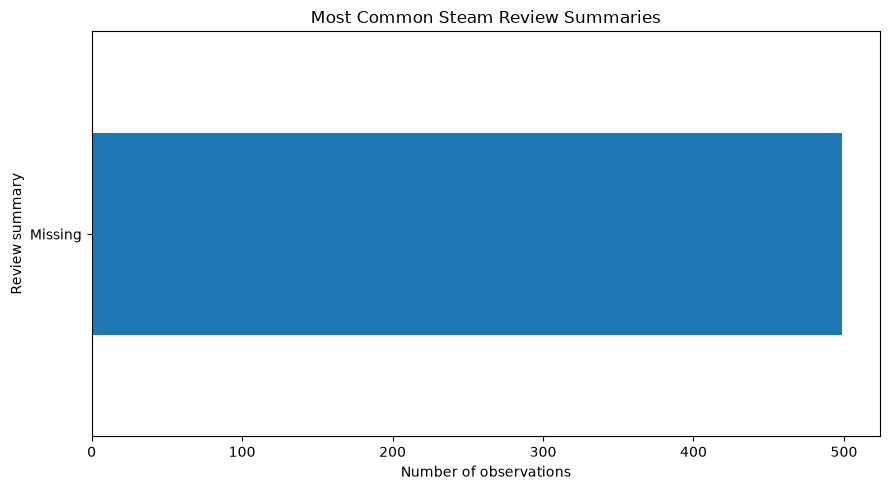

In [5]:
review_counts = observations["review_summary"].fillna("Missing").value_counts().head(12)
plt.figure(figsize=(9, 5))
review_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of observations")
plt.ylabel("Review summary")
plt.title("Most Common Steam Review Summaries")
plt.tight_layout()
plt.show()

## 5. Chart 4 — Daily median price

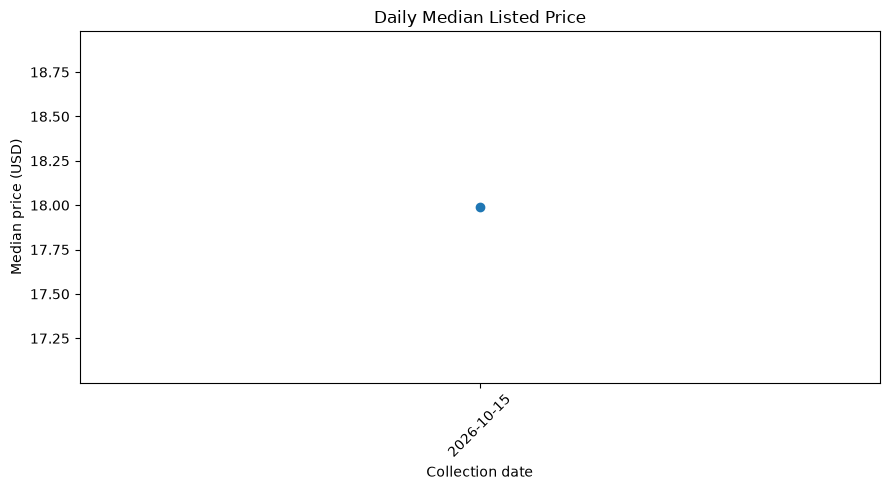

,median_price_usd
scraped_at,
2026-10-15,17.99


In [6]:
daily_price = observations.groupby(observations["scraped_at"].dt.date)["price"].median().dropna()
plt.figure(figsize=(9, 5))
plt.plot(daily_price.index.astype(str), daily_price.values, marker="o")
plt.xlabel("Collection date")
plt.ylabel("Median price (USD)")
plt.title("Daily Median Listed Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(daily_price.to_frame("median_price_usd"))

## 6. Chart 5 — Rank trends for the five most frequently observed titles

In [7]:
top_titles = observations["title"].value_counts().head(5).index
trend = observations[observations["title"].isin(top_titles)].copy()
trend = trend.sort_values("scraped_at")
plt.figure(figsize=(10, 6))
for title, group in trend.groupby("title"):
    plt.plot(group["scraped_at"].dt.strftime("%Y-%m-%d"), group["rank"], marker="o", label=title)
plt.gca().invert_yaxis()
plt.xlabel("Collection date")
plt.ylabel("Rank (1 is highest)")
plt.title("Ranking Trends for Five Frequently Observed Titles")
plt.xticks(rotation=45)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

KeyError: 'title'

## 7. Chart 6 — Discounted versus not discounted

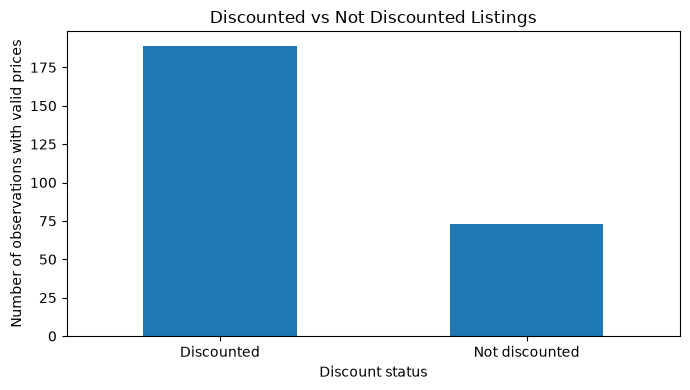

Valid-price observations: 262
Discounted share (%): 72.14
Mean calculated discount (%): 45.58


In [8]:
valid_discount = observations[observations["price"].notna() & observations["original_price"].notna()].copy()
valid_discount["is_discounted"] = (
    (valid_discount["original_price"] > valid_discount["price"]) &
    (valid_discount["original_price"] > 0)
)
discount_counts = valid_discount["is_discounted"].value_counts().rename(index={True:"Discounted", False:"Not discounted"})
plt.figure(figsize=(7, 4))
discount_counts.plot(kind="bar")
plt.xlabel("Discount status")
plt.ylabel("Number of observations with valid prices")
plt.title("Discounted vs Not Discounted Listings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if len(valid_discount):
    print("Valid-price observations:", len(valid_discount))
    print("Discounted share (%):", round(valid_discount["is_discounted"].mean()*100, 2))
    calculated = ((valid_discount["original_price"]-valid_discount["price"])/valid_discount["original_price"]*100)
    calculated = calculated[valid_discount["original_price"] > 0]
    print("Mean calculated discount (%):", round(calculated.mean(), 2))
else:
    print("No observations have both current and original prices.")

## 8. Original question — Which games had the largest rank range?

In [9]:
rank_summary = observations.dropna(subset=["game_id", "rank"]).groupby(["game_id", "title"])["rank"].agg(
    observations="count", best_rank="min", worst_rank="max", mean_rank="mean"
).reset_index()
rank_summary["rank_range"] = rank_summary["worst_rank"] - rank_summary["best_rank"]
rank_summary = rank_summary[rank_summary["observations"] >= 2].sort_values("rank_range", ascending=False)
display(rank_summary.head(20))

KeyError: 'title'

## 9. Review summary versus price (descriptive comparison, not causal)

In [10]:
review_price = observations.dropna(subset=["review_summary", "price"]).groupby("review_summary")["price"].agg(
    count="count", median_price="median", mean_price="mean"
).sort_values("count", ascending=False)
display(review_price.head(15))

,count,median_price,mean_price
review_summary,,,


## 10. Interpretation notes for the report
For each chart, write 2–4 sentences answering:
- What does the chart show?
- What specific numbers support your statement?
- What are the limitations (missing values, changing ranks, regional prices)?
- Does it answer one of the assignment questions?

**Do not claim that ranking equals sales volume.** Steam Top Sellers is a revenue-related ranking and can include non-game items. Review summary is categorical, not a numerical rating. The brand/seller question should be explicitly adapted to an attribute actually present in your dataset.